# Análisis ConnectaTel


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarse con la estructura de los tres datasets**.  
En esta etapa, valido que los archivos se carguen correctamente, conozco sus columnas y tipos de datos, y detecto posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código


In [ ]:
print(plans.head(5))# mostrar las primeras 5 filas de plans

  plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  


In [ ]:
print(users.head(5))# mostrar las primeras 5 filas de users

   user_id first_name last_name  age      city                       reg_date  \
0    10000     Carlos    Garcia   38  Medellín  2022-01-01 00:00:00.000000000   
1    10001      Mateo    Torres   53         ?  2022-01-01 06:34:17.914478619   
2    10002      Sofia   Ramirez   57      CDMX  2022-01-01 13:08:35.828957239   
3    10003      Mateo   Ramirez   69    Bogotá  2022-01-01 19:42:53.743435858   
4    10004      Mateo    Torres   63       GDL  2022-01-02 02:17:11.657914478   

      plan churn_date  
0   Basico        NaN  
1   Basico        NaN  
2   Basico        NaN  
3  Premium        NaN  
4   Basico        NaN  


In [ ]:
print(usage.head(5))# mostrar las primeras 5 filas de usage

   id  user_id  type                           date  duration  length
0   1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1   2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2   3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3   4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4   5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN


**Tip:** Si no usar `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisar el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usar `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Contar valores nulos por columna para cada dataset.
- Calcular la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>

Usar `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())# Cantidad de valores nulos)
print(users.isna().mean())# Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ 
### Diagnóstico de valores nulos

**users**

- **`city` (469 nulos, 11.7 %)**: está en el rango de 5 % a 30 %, así que se investiga antes de decidir.
  **Acción:** dejar los nulos y reemplazarlos por "Desconocida" (junto con los `?`, que también son faltantes).
  **Justificación:** eliminar 1 de cada 9 clientes sesgaría el análisis, e inventar una ciudad sería peor.

- **`churn_date` (3534 nulos, 88.4 %)**: supera el 80-90 %, pero el nulo tiene significado.
  **Acción:** conservar la columna sin imputar y crear una variable `churned` (True si tiene fecha).
  **Justificación:** un nulo significa "cliente activo", y la columna es la base del análisis de churn, así que no se elimina.

- **Resto de columnas (`user_id`, `first_name`, `last_name`, `age`, `reg_date`, `plan`)**: 0 % de nulos.
  **Acción:** ninguna por ahora.
  **Justificación:** no tienen faltantes, aunque en el paso 2.2 se revisan valores inconsistentes.

**usage**

- **`date` (50 nulos, 0.125 %)**: está por debajo del 5 %.
  **Acción:** dejar como nulos y excluirlos solo en análisis que dependan de la fecha.
  **Justificación:** es una proporción mínima y los eventos conservan su duración o longitud.

- **`duration` (22076 nulos, 55.2 %)**: nulo estructural, corresponde a los mensajes (`type = text`).
  **Acción:** dejar como nulos, sin imputar.
  **Justificación:** un mensaje no tiene duración, y rellenar con 0 o la media distorsionaría las estadísticas de llamadas.

- **`length` (17896 nulos, 44.7 %)**: nulo estructural, corresponde a las llamadas (`type = call`).
  **Acción:** dejar como nulos, sin imputar.
  **Justificación:** una llamada no tiene longitud de mensaje, y el análisis de mensajes debe filtrar por `type`.

- **`id`, `user_id`, `type`**: 0 % de nulos.
  **Acción:** ninguna.
  **Justificación:** no tienen faltantes.

**Observación adicional:** los nulos de `duration` y `length` suman 39972, 28 menos que las 40000 filas. Hay al menos 28 eventos con ambos campos llenos, lo cual no es lógico, y se investiga en el paso 2.2.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explorar las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explorar las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [ ]:
usage.describe()# explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


## Detección de Valores invalidos y sentinels
*numericas de users

- `user_id`: identificador consecutivo de 10000 a 13999, sin valores anómalos.
- `age`: el mínimo es -999, un sentinel que no corresponde a una edad real. Distorsiona la media (33.7 vs. mediana 47) y la desviación estándar (123). Sin él, el máximo de 79 es razonable.

* numericas de usage

- `id` y `user_id`: identificadores sin anomalías aparentes; `user_id` está en el mismo rango que en `users` (10000 a 13999).
- `duration`: distribución sesgada a la derecha (media 5.2 vs. mediana 3.5), con mínimo de 0 y un máximo de 120 muy alejado del percentil 75. Se revisarán los ceros y los extremos.
- `length`: mínimo de 0 (mensajes de longitud cero, poco lógicos) y máximo de 1490, muy alejado del percentil 75 (64). Se analizará como posible outlier.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f"--- {col} ---")
    print(users[col].value_counts(dropna=False))
    print()


--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



## Hallazgos
La columna `city`
- city	8 valores: 6 ciudades y dos formas de faltante, 469 NaN y 96 ?. En total faltan 565 ciudades (14.1 %), más de lo que mostraba .info().

La columna `plan`
- Solo Basico (2595, 64.9 %) y Premium (1405, 35.1 %). Está limpio y el merge con plans funcionará.

In [ ]:
# explorar columna categórica de usage
usage['type'] 
# completa el código
for col in usage:
    print(f"--- {col} ---")
    print(usage[col].value_counts(dropna=False))
    print()

--- id ---
2049     1
35492    1
25241    1
31386    1
29339    1
        ..
17730    1
19779    1
30020    1
32069    1
2047     1
Name: id, Length: 40000, dtype: int64

--- user_id ---
13819    27
13100    22
13772    22
13255    22
13475    21
         ..
12448     2
11891     2
10226     2
13923     2
12058     1
Name: user_id, Length: 3999, dtype: int64

--- type ---
text    22092
call    17908
Name: type, dtype: int64

--- date ---
NaN                              50
2024-03-27 18:40:27.360684017     1
2024-04-28 16:12:53.299332482     1
2024-01-13 12:10:40.456011400     1
2024-03-21 23:46:17.019425485     1
                                 ..
2024-05-03 03:24:20.466511662     1
2024-05-10 04:43:02.344558614     1
2024-05-22 00:16:44.425110626     1
2024-03-23 15:11:39.047476186     1
2024-04-14 19:01:18.031950798     1
Name: date, Length: 39951, dtype: int64

--- duration ---
NaN      22076
0.21        47
0.84        43
0.02        43
0.03        43
         ...  
19.32        1

## Hallazgos
La columna `type`
- Solo call (17908) y text (22092). Está limpio.


### Diagnóstico: valores inválidos o sentinels

**¿En qué columnas encontré valores inválidos o sentinels?**

- **`users.age`**: contiene el sentinel **-999**, visto en el mínimo del `describe()`. Distorsiona la media (33.7 frente a una mediana de 47) y la desviación estándar (123).
- **`users.city`**: contiene el sentinel **`?`** en 96 registros. Sumados a los 469 nulos, hay 565 ciudades desconocidas (14.1 %).
- **`usage.length`**: tiene un mínimo de 0 (mensajes sin longitud, poco lógico) y un máximo de 1490, muy lejos del percentil 75 (64). Es un valor sospechoso, pendiente de confirmar.
- **`usage.duration`**: tiene un mínimo de 0 (llamadas sin duración, que pueden ser llamadas perdidas) y un máximo de exactamente 120, lejos del percentil 75 (6.99). Es un valor sospechoso, pendiente de confirmar.
- **`usage` (`type` frente a `duration` y `length`)**: hay más valores no nulos de los esperados (16 llamadas y 12 mensajes de más). Algunos eventos tienen un campo que no corresponde a su tipo. Es una inconsistencia lógica, pendiente de confirmar.
- **`plan` y `type`**: sin valores inválidos.

**¿Qué acción tomaría?**

- **`age` (-999)**: reemplazar por `NaN`. Así se conservan los datos de uso y de churn de esos clientes y se evita que distorsionen las estadísticas.
- **`city` (`?`)**: reemplazar por `NaN` y rellenar todos los faltantes con "Desconocida". Eliminar 14 % de los clientes sesgaría el análisis.
- **`length = 0`**: convertir a `NaN`, porque un mensaje sin longitud es un error de registro.
- **`duration = 0`**: conservar como llamadas perdidas o no contestadas, y analizarlas aparte si son muchas.
- **`duration` máximo (120) y `length` máximo (1490)**: no eliminar todavía. Se evalúan con IQR y boxplots en el paso de outliers, porque pueden ser comportamiento real o fraude.
- **`type` frente a `duration` y `length`**: poner en `NaN` el campo que no corresponde al tipo (`length` en las llamadas y `duration` en los mensajes).

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Conviertir las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisar cuántas veces aparece cada año.
- Identificar fechas imposibles (ej. años futuros o negativos).

Datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')# completa el código

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date` los registros se distribuyen de forma pareja entre 2022 (1314), 2023 (1316) y 2024 (1330). Sin embargo, hay **40 registros con año 2026**, una fecha futura frente al límite de 2024 de los datos, por lo que corresponden a errores de captura. No hay nulos tras la conversión (los 4000 registros son fechas válidas).

**Acción recomendada:** convertir esas 40 fechas a `NaT` (nulo) en vez de eliminar los clientes. Así se conservan su plan, su uso y su churn, y solo se pierde la fecha de registro, que no es crítica para el análisis de uso

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()


2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, de usage todos los eventos con fecha (39950) corresponden al año 2024, coherente con el periodo del análisis. No hay años futuros ni fuera de rango. Los únicos faltantes son los 50 nulos que ya se habían detectado (0.125 %), y la conversión no generó fechas inválidas adicionales.

### Diagnóstico: fechas fuera de rango

**¿Aparecen años imposibles?**

- **`users.reg_date`**: sí. Hay **40 registros con año 2026**, una fecha futura frente al límite de 2024 de los datos. Los demás años son 2022 (1314), 2023 (1316) y 2024 (1330), sin años muy antiguos. Los 40 de 2026 son errores de captura.
- **`usage.date`**: no. Los 39950 eventos con fecha son de 2024, el periodo esperado. Los 50 nulos ya estaban antes de convertir, así que la conversión no creó fechas inválidas.
- **`users.churn_date`**: [pendiente: completar con los años que salgan al ejecutar `users['churn_date'].dt.year.value_counts(dropna=False).sort_index()`. Se espera 2022 a 2024, más 3534 nulos, que son clientes activos.]

**¿Qué haría con ellas?**

- **`reg_date` de 2026**: convertir esas 40 fechas a `NaT` en lugar de eliminar los clientes.
  **Justificación:** son solo el 1 % de la base, y así se conservan su plan, su uso y su churn. Se pierde únicamente la fecha de registro, que no es crítica para el análisis de uso.
- **`usage.date`**: no se requiere corrección de años. Dejar los 50 nulos y excluirlos solo en análisis que dependan de la fecha.
- **`churn_date`**: [pendiente: si aparece algún año posterior a 2024, convertirlo a `NaT]. Además, revisar que ninguna baja sea anterior al registro.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplazar el sentinel **-999** con la mediana.
- En `city`, reemplazar el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marcar como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())  # debería ser 565 (469 + 96)
users['city'].value_counts(dropna=False)


565


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].isna().sum())  # debería ser 40
print(users['reg_date'].max())         # debería estar en 2024
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()


40
2024-12-31 00:00:00


2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verificar si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda s: s.isna().mean())


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda s: s.isna().mean())


type
call    0.99933
text    0.00000
Name: length, dtype: float64

### Diagnóstico: nulos en `duration` y `length`

**Qué veo**

- `duration` tiene 22076 nulos (55.2 %). Las llamadas (`call`) tienen 0 % de nulos y los mensajes (`text`) tienen 99.93 %.
- `length` tiene 17896 nulos (44.7 %). Los mensajes (`text`) tienen 0 % de nulos y las llamadas (`call`) tienen 99.93 %.
- En ambos casos la ausencia depende de la columna `type`, una variable observada, por lo que los nulos son **MAR**.
- Hay unos 28 eventos inconsistentes (16 mensajes con `duration` y 12 llamadas con `length`), un 0.07 % de `usage`.

**Acción recomendada**

- **`duration` y `length`:** dejarlos como nulos, sin imputar.
  **Justificación:** una llamada no tiene longitud de mensaje y un mensaje no tiene duración; rellenar con 0 o con la media distorsionaría las estadísticas.
- **Análisis posteriores:** filtrar por `type` (`call` para `duration`, `text` para `length`).
  **Justificación:** así cada variable se calcula solo sobre los eventos donde tiene sentido.
- **Los 28 eventos inconsistentes:** dejarlos documentados, o poner en `NaN` el campo que no corresponde a su tipo.
  **Justificación:** el impacto es mínimo (0.07 %), pero evita que contaminen los promedios.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construir una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombrar las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combinar esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg(
    cant_mensajes=("is_text", "sum"),
    cant_llamadas=("is_call", "sum"),
    cant_minutos_llamada=("duration", "sum")
).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtener un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisar la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
cols_numericas = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[cols_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
(user_profile["plan"].value_counts(normalize=True) * 100).round(2)


Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribir un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usar `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usar `palette=['skyblue','green']`
- Agregar título y etiquetas

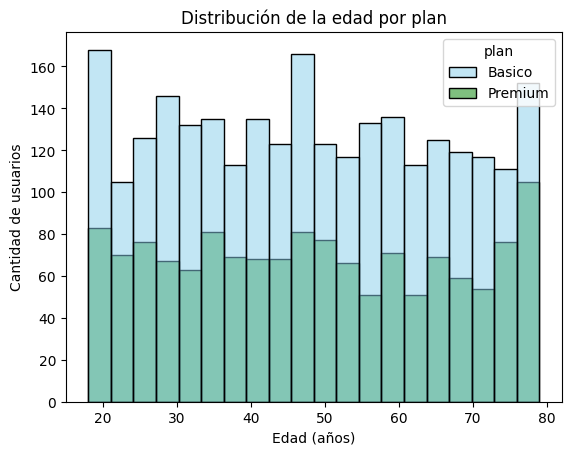

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan',
             hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
La edad tiene una distribución aproximadamente uniforme, sin sesgo: va de 18 a 79 años y la media (48.1) coincide con la mediana (48). Los planes Basico y Premium tienen la misma forma, y Premium es proporcionalmente más pequeño (35 % frente a 65 %), por lo que no existe un patrón claro de edad según el plan. La barra cercana a los 48 años es algo más alta en Basico, probablemente por la imputación de la mediana en los registros que tenían -999.

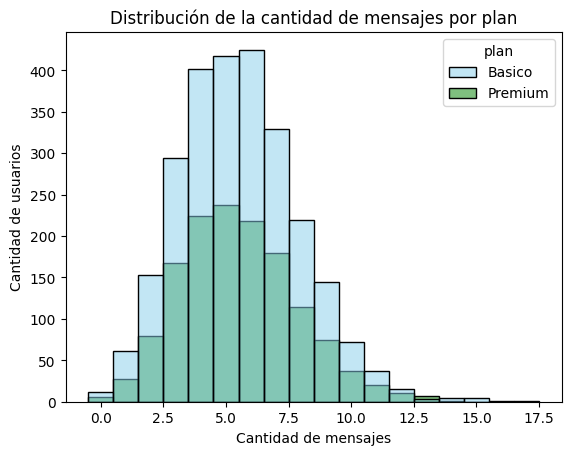

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan',
             hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de la cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La cantidad de mensajes tiene una distribución con un solo pico entre 4 y 6 mensajes, ligeramente sesgada a la derecha: la cola se extiende hasta 17 mensajes y la media (5.5) es un poco mayor que la mediana (5). Los planes Basico y Premium tienen la misma forma y el mismo pico; las barras de Premium son más bajas solo porque hay menos clientes en ese plan (35 % frente a 65 %). No existe un patrón claro de mensajes según el plan. Los usuarios con más de 11 mensajes son pocos y se evaluarán como posibles outliers.

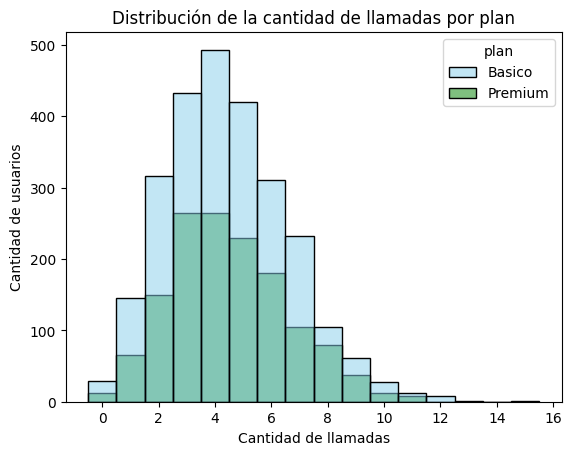

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan',
             hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de la cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La cantidad de llamadas tiene una distribución con un solo pico en 4 llamadas y una cola larga a la derecha que llega hasta 15, es decir, está sesgada a la derecha (media de 4.5 frente a mediana de 4). Los planes Basico y Premium tienen la misma forma y el mismo pico; las barras de Premium son más bajas solo porque hay menos clientes en ese plan (35 % frente a 65 %). No existe un patrón claro de llamadas según el plan. Los usuarios con más de 10 llamadas son pocos y se evaluarán como posibles outliers.

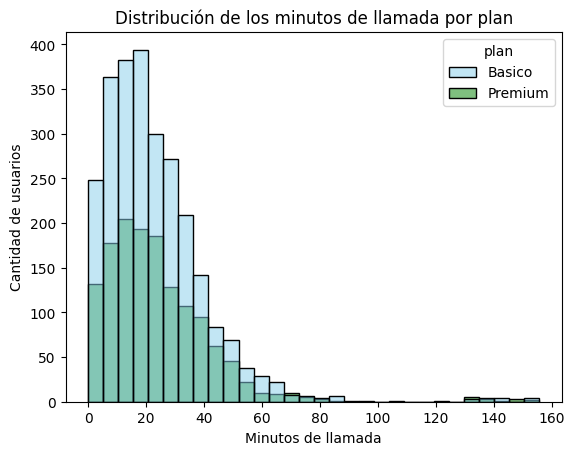

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan',
             hue_order=['Basico', 'Premium'],
             palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de los minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- Los minutos de llamada tienen una distribución sesgada a la derecha: el pico está entre 10 y 25 minutos, la media (23.3) supera a la mediana (19.8) y la cola llega hasta unos 155 minutos. Basico y Premium tienen la misma forma en la parte principal, con Premium más bajo por tener menos clientes (35 % frente a 65 %), por lo que no hay un patrón claro según el plan. Se observa un pequeño grupo de usuarios con más de 130 minutos, separado del resto por un hueco, que parece concentrarse en Premium y se evaluará como posible outlier (uso real muy alto, fraude o error de registro).

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usar **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crear un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responder si **existen o no outliers** en las variables.  
- Si hay outliers, crear otro bucle para calcular los límites de esas columnas usando el **método IQR** y decidir qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

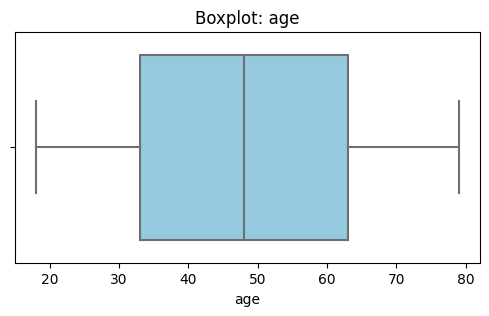

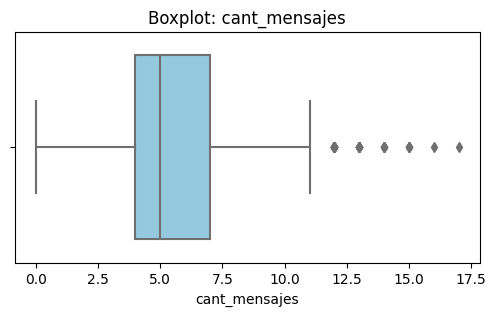

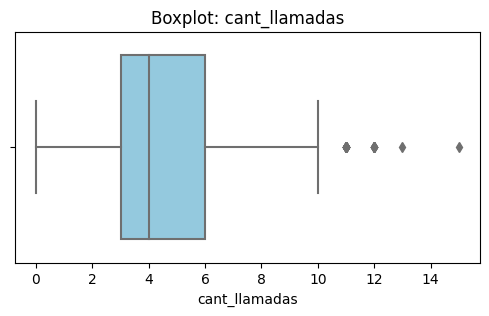

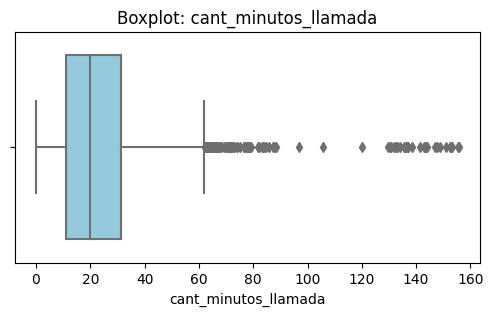

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- `age`: no hay outliers. Los bigotes llegan a 18 y 79 años y no hay puntos fuera de ellos.
- `cant_mensajes`: hay outliers solo a la derecha (por encima de unos 11 mensajes, hasta 17). Se conservan, porque son conteos plausibles de usuarios con uso intensivo.
- `cant_llamadas`: hay outliers solo a la derecha (por encima de unas 10 llamadas, hasta 15). Se conservan por la misma razón.
- `cant_minutos_llamada`: hay muchos outliers solo a la derecha (por encima de unos 62 minutos, hasta unos 155), con un grupo separado de más de 130 minutos. Se conservan, pero ese grupo se marca para revisión por su posible relación con fraude, errores de registro o uso real muy alto.

Como solo hay outliers del lado derecho, se calculó únicamente el límite superior con IQR.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    pct = n_outliers / len(user_profile) * 100
    print(f"{col}: límite superior = {limite_superior:.2f} | outliers = {n_outliers} ({pct:.2f} %)")



cant_mensajes: límite superior = 11.50 | outliers = 46 (1.15 %)
cant_llamadas: límite superior = 10.50 | outliers = 30 (0.75 %)
cant_minutos_llamada: límite superior = 61.86 | outliers = 109 (2.73 %)


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡**Insights**

* **`cant_mensajes`: se mantienen los outliers.** El límite superior es 11.5 y hay 46 usuarios por encima (1.15 %), con un máximo de 17. Son conteos plausibles de usuarios con uso intensivo, cercanos al umbral, y no hay evidencia de errores de registro. Eliminarlos haría perder información sobre los clientes más activos.

* **`cant_llamadas`: se mantienen los outliers.** El límite superior es 10.5 y hay 30 usuarios por encima (0.75 %), con un máximo de 15. Es una proporción mínima y los valores son plausibles, así que no distorsionan el análisis y representan comportamiento real.

* **`cant_minutos_llamada`: se mantienen los outliers, pero se marca el grupo extremo.** El límite superior es 61.86 y hay 109 usuarios por encima (2.73 %), con un máximo de 155.69 (unas 2.5 veces el límite). Reflejan uso muy alto de llamadas, no necesariamente errores. Los usuarios con más de 100 minutos, separados del resto por un hueco en la distribución, se marcan con una columna aparte para analizarlos en la segmentación (posible fraude, error de registro o uso real muy alto).

En los tres casos no se eliminan datos, porque los outliers representan comportamientos reales de uso intensivo, relevantes para diseñar planes y estrategias de retención.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crear una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usar comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),
]
categorias = ['Bajo uso', 'Uso medio']

user_profile['grupo_uso'] = np.select(condiciones, categorias, default='Alto uso')

# verificación
user_profile['grupo_uso'].value_counts()


Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crear una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usar comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60,
]
categorias_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(condiciones_edad, categorias_edad, default='Adulto Mayor')

# verificación
user_profile['grupo_edad'].value_counts()


Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crear dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agregar título y etiquetas a los ejes en cada gráfico.

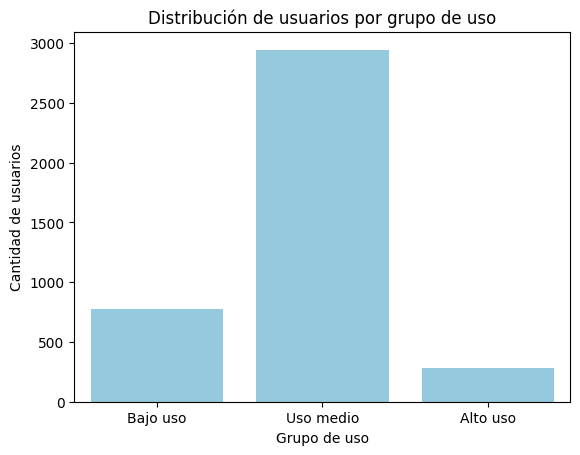

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso',
              order=['Bajo uso', 'Uso medio', 'Alto uso'],
              color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

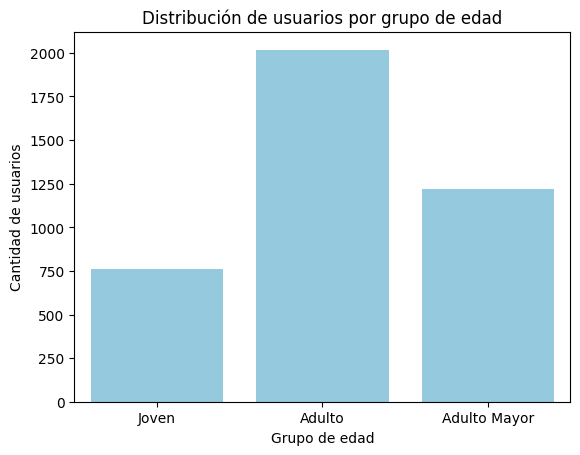

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad',
              order=['Joven', 'Adulto', 'Adulto Mayor'],
              color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 


### Análisis ejecutivo

#### ⚠️ Problemas detectados en los datos

- **Edad (`age`):** Se identificaron aproximadamente 55 registros con el valor centinela `-999` (1,4 %), que fueron reemplazados por la mediana de 48 años.
- **Ciudad (`city`):** Se encontraron 469 valores nulos y 96 registros con el valor `?`, para un total de 565 registros (14,1 %). Estos valores se dejaron como nulos.
- **Fecha de registro (`reg_date`):** Se detectaron 40 fechas posteriores al límite establecido de 2024 (1,0 %), que fueron marcadas como nulas.
- **Fecha de uso (`date`):** Se identificaron 50 registros con fechas nulas (0,125 %), que se conservaron sin imputar.
- **Duración y longitud de los eventos (`duration` / `length`):** Los valores nulos dependen del tipo de evento y no necesariamente representan errores. Se conservaron sin imputar. Sin embargo, se deben verificar aproximadamente 28 eventos que presentan información en el campo que no corresponde a su tipo.

#### 🔍 Segmentos por Edad

- **Jóvenes (menores de 30 años):** Representan el 19,0 % de los usuarios.
- **Adultos (30-59 años):** Constituyen el 50,5 % de la base de usuarios y son el grupo más numeroso.
- **Adultos mayores (60 años o más):** Representan el 30,6 % de los usuarios.
- **Relación entre edad y uso:** Es necesario contrastar las tablas 2 y 4 para determinar si existen diferencias en el nivel de uso entre los grupos de edad. Si los porcentajes son similares, se podrá concluir que la edad no parece determinar el nivel de uso.

#### 📊 Segmentos por Nivel de Uso

- **Bajo uso:** Representa el 19,5 % de los usuarios (778 personas). Es un segmento que podría tener menor vinculación con el servicio y que requiere estrategias de activación y retención.
- **Uso medio:** Constituye el 73,6 % de los usuarios (2.943 personas). Es el segmento predominante y, por su tamaño, tiene un peso importante en los ingresos totales.
- **Alto uso:** Representa el 7,0 % de los usuarios (279 personas). Son los clientes más activos y podrían generar oportunidades de ingresos adicionales mediante la migración a planes superiores o la contratación de servicios extra.
- **Distribución por plan:** El 64,9 % de los usuarios tiene el plan Básico y el 35,1 % el plan Premium. Es necesario revisar las tablas 1 y 3 para determinar qué plan concentra a los usuarios de alto y bajo uso.
- **Uso extremo (outliers):** Se identificaron 46 usuarios con valores atípicos en mensajes (1,15 %), 30 en llamadas (0,75 %) y 109 en minutos (2,73 %). En la distribución de minutos se observa un grupo de usuarios que supera los 100 minutos y se encuentra separado del resto de la distribución. Estos casos se conservaron porque no existe evidencia suficiente para considerarlos errores.

#### ➡️ Esto sugiere que...

La mayor parte de los usuarios presenta un nivel de uso medio, mientras que una minoría concentra el uso más elevado. Por ello, las estrategias comerciales deberían priorizar el comportamiento de los clientes y su nivel de actividad, en lugar de basarse exclusivamente en la edad.

Los usuarios de alto uso representan una oportunidad potencial de crecimiento, mientras que los de bajo uso requieren acciones para aumentar su participación y reducir el riesgo de abandono. La distribución del uso entre los planes y las diferencias de churn deben confirmarse con las tablas correspondientes antes de establecer conclusiones definitivas.

#### 💡 Recomendaciones

1. **Impulsar la migración a Premium:** Identificar a los usuarios de alto uso que todavía tienen el plan Básico y ofrecerles el plan Premium, cuyo precio es de 25 USD frente a los 12 USD del Básico, siempre que la oferta se ajuste a sus necesidades.

2. **Activar y retener a los clientes de bajo uso:** Diseñar campañas personalizadas, incentivos y comunicaciones que fomenten un mayor uso del servicio y permitan detectar a los clientes con riesgo de abandono.

3. **Segmentar según el comportamiento:** Comparar el nivel de uso por edad y por plan. Si las diferencias por edad son pequeñas, priorizar la actividad del cliente como criterio para personalizar las ofertas.

4. **Mejorar la calidad de los datos:** Corregir los procesos de captura de ciudad y fecha de registro para reducir los valores faltantes y mejorar los análisis geográficos y de antigüedad.

5. **Investigar los valores extremos:** Revisar con el equipo técnico a los usuarios que superan los 100 minutos para determinar si corresponden a un comportamiento legítimo, errores de registro o posibles anomalías.

6. **Evaluar la retención por plan:** Contrastar las tasas de churn de los usuarios Básicos y Premium para identificar qué segmento necesita mayores esfuerzos de fidelización y comprobar el valor real del plan Premium.

